# Predicting Bench Press Strength Using Machine Learning

## 1. Introduction

The goal of our project is to predict a powerlifter's best bench press in kilograms. We will produce this prediction through using various input features such as bodyweight, sex, and age.

We will investigate whether including the features age and sex along with bodyweight improves prediction accuracy.

This project will be using regression as we are trying to predict a continuous numerical value. We will use the following two algorithms:
- Linear regression (implemented from scratch)
- Random Forest Regressor

## 2. Dataset Preparation

Before we can begin training our models we must first prepare the data. We will load, inspect, and clean the dataset. 

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SOURCE=Path('Dataset/openpowerlifting-latest/openpowerlifting-2026-09-19/openpowerlifting-2026-09-19-ed07773f.csv')
RESULTS=Path('results')
FIGURES=RESULTS/'figures'
FIGURES.mkdir(parents=True,exist_ok=True)
sns.set_theme(style='whitegrid')
print('Python',platform.python_version(),'| scikit-learn',sklearn.__version__)
if not SOURCE.is_file():
    raise FileNotFoundError(f'Place the original September 19 dataset at {SOURCE}')


Python 3.12.5 | scikit-learn 1.9.1


In [2]:
import pandas as pd

df = pd.read_csv("Dataset/openpowerlifting-latest/openpowerlifting-2026-09-19/openpowerlifting-2026-09-19-ed07773f.csv")

df.head()

C:\Users\saheb\AppData\Local\Temp\ipykernel_10252\2131738008.py:3: DtypeWarning: Columns (33: State, 35: ParentFederation, 38: MeetState) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Dataset/openpowerlifting-latest/openpowerlifting-2026-09-19/openpowerlifting-2026-09-19-ed07773f.csv")


,Name,Sex,Event,Equipment,Age,AgeClass,BirthYearClass,Division,BodyweightKg,WeightClassKg,...,Country,State,Federation,ParentFederation,Date,MeetCountry,MeetState,MeetTown,MeetName,Sanctioned
0,E.S. Denisenko,F,B,Raw,28.5,24-34,24-39,Open,67.3,NaN,...,Belarus,NaN,GSF-Belarus,NaN,2019-06-22,Belarus,NaN,Luninets,Bison Power Cup,Yes
1,I.S. Lebetskaya,F,B,Raw,43.5,40-44,40-49,Open,73.2,NaN,...,Belarus,NaN,GSF-Belarus,NaN,2019-06-22,Belarus,NaN,Luninets,Bison Power Cup,Yes
2,K. Yakimovich,F,B,Raw,26.5,24-34,24-39,Open,60.6,NaN,...,Belarus,NaN,GSF-Belarus,NaN,2019-06-22,Belarus,NaN,Luninets,Bison Power Cup,Yes
3,A.G. Golneva,F,B,Raw,19.5,20-23,19-23,Juniors 17-21,50.3,NaN,...,Belarus,NaN,GSF-Belarus,NaN,2019-06-22,Belarus,NaN,Luninets,Bison Power Cup,Yes
4,E.V. Marunevskaya,F,B,Raw,19.5,20-23,19-23,Juniors 17-21,63.7,NaN,...,Belarus,NaN,GSF-Belarus,NaN,2019-06-22,Belarus,NaN,Luninets,Bison Power Cup,Yes


### Initial Data Exploration

Before we begin cleaning the dataset we will start by examining the data's structure and contents. We will investigate the total number of rows and columns, available features, and any possible data quality issues.

This exploration will help determine which data is relevant for our model as well as what preprocessing is needed.

In [3]:
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (4034178, 42)

Columns:
['Name', 'Sex', 'Event', 'Equipment', 'Age', 'AgeClass', 'BirthYearClass', 'Division', 'BodyweightKg', 'WeightClassKg', 'Squat1Kg', 'Squat2Kg', 'Squat3Kg', 'Squat4Kg', 'Best3SquatKg', 'Bench1Kg', 'Bench2Kg', 'Bench3Kg', 'Bench4Kg', 'Best3BenchKg', 'Deadlift1Kg', 'Deadlift2Kg', 'Deadlift3Kg', 'Deadlift4Kg', 'Best3DeadliftKg', 'TotalKg', 'Place', 'Dots', 'Wilks', 'Glossbrenner', 'Goodlift', 'Tested', 'Country', 'State', 'Federation', 'ParentFederation', 'Date', 'MeetCountry', 'MeetState', 'MeetTown', 'MeetName', 'Sanctioned']


### Examining Categorical Variables

The dataset consisted of 4,034,178 entries and 42 columns. We will examine the values within Equipment, Event, and Sex columns in order to help in understanding how the data is categorized. This will help determine which entries are suitable for our project.

In [4]:
print("Equipment categories:")
print(df["Equipment"].value_counts(dropna=False))

print("\nEvent categories:")
print(df["Event"].value_counts(dropna=False))

print("\nSex categories:")
print(df["Sex"].value_counts(dropna=False))

Equipment categories:
Equipment
Raw           1921815
Single-ply    1415253
Unlimited      324336
Wraps          241456
Multi-ply      131199
Straps            119
Name: count, dtype: int64

Event categories:
Event
SBD    2913631
B       799289
D       218889
BD       75753
S        19943
SB        4185
SD        2488
Name: count, dtype: int64

Sex categories:
Sex
M     2906204
F     1127775
Mx        199
Name: count, dtype: int64


### Findings from Categorical Data Exploration

The dataset contains six different equipment categories. For our project we want to focus on unequipped lifting which would be the Raw category.

The Raw category contains a total of 1,921,815 entries. We will use only entries classified as Raw. This will help prevent equipped lifting from influencing our predictions.

We examined the various event categories as well. We will include all events that include bench press which will be the following:
- SBD (Squat, Bench, Deadlift)
- B (Bench)
- BD (Bench, Deadlift)
- SB (Squat, Bench)

The sex column contains a total of three categories which are M (Male), F (Female), and Mx (Mix). The Mx category only contains 199 entries so we will consider how to handle this category during preprocessing.

### Filtering the Dataset

Based on the initial exploration we will now filter the dataset to only include the RAW category and within the RAW category we will filter for only events containing bench press as discussed above. 

In [5]:
# Keep only raw lifting entries involving bench press
raw_df = df[
    (df["Equipment"] == "Raw") &
    (df["Event"].isin(["SBD", "B", "BD", "SB"]))
].copy()

print("Original entries:", len(df))
print("Filtered entries:", len(raw_df))

Original entries: 4034178
Filtered entries: 1745981


### Filtered dataset findings

Filtering the dataset reduced the entries from 4,034,178 entries to 1,745,981 entires.

### Checking for Missing Values

Now that the dataset is filtered we will check for any missing values.

The relevant columns for our predictions are:
- BodyweightKg
- Age
- Sex
- Best3BenchKg (Best bench of 3 attempts)

These are the columns we will inspect for missing values.

In [6]:
# Columns relevant to our prediction
columns = ["BodyweightKg", "Age", "Sex", "Best3BenchKg"]

# Count missing values in each column
print(raw_df[columns].isnull().sum())

BodyweightKg      6858
Age             257462
Sex                  0
Best3BenchKg     46683
dtype: int64


### Missing value Findings

After checking fro missing values we can see that BodyweightKg and Best3BenchKg have few missing values in relation to the total dataset. The Age column however has a larger proportion of missing data with approximately 14.75% of entries missing age data. The Sex column contains zero missing entries. 

Given the large size of the dataset we have decided to remove all entries with missing values including the missing Age entries. This will still leave sufficient data for training and evaluating the models.

Removing age entries may however affect how representative the final dataset is. 

### Data Validation

Before we begin cleaning the dataset we will examine the values for age, bodyweight, and best bench press.

We will check for invalid or unusual values as well as the minimum and maximum values. 

This will help determine determine what exactly we should remove and determine which records will be suitable for our models.

In [7]:
# Numerical columns to validate
numeric_cols = ["Age", "BodyweightKg", "Best3BenchKg"]

# Display descriptive statistics
display(raw_df[numeric_cols].describe())

# Count zero or negative values
print("Zero or negative values:")
print((raw_df[numeric_cols] <= 0).sum())

,Age,BodyweightKg,Best3BenchKg
count,1.488519e+06,1.739123e+06,1.699298e+06
mean,3.043370e+01,8.390345e+01,1.123506e+02
std,1.309575e+01,2.167729e+01,4.645848e+01
min,0.000000e+00,1.642000e+01,-3.150000e+02
25%,2.050000e+01,6.766000e+01,7.250000e+01
50%,2.650000e+01,8.165000e+01,1.125000e+02
75%,3.700000e+01,9.720000e+01,1.450000e+02
max,1.055000e+02,2.850000e+02,3.550000e+02


Zero or negative values:
Age                2
BodyweightKg       0
Best3BenchKg    1404
dtype: int64


### Data Validation Findings

Two of the validated columns contain values that are either zero or negative. For Age this means the entries are invalid and thus will be removed. For the best bench column the zero values may be real values but since our goal is to predict successful bench press results, these entries will be excluded. 

The Age column contained a maximum recorded age of 105.5 years which is unusually high. This value should be investigated further.

Bodyweight ranged from 16.42 kg up to 285 kg. These values are extreme but are not necessarily incorrect. Bodyweight did not contain any zero or negative entries.

### Investigating Unusual Ages

In [8]:
# Identify entries with unusually low or high ages
young_lifters = raw_df[raw_df["Age"] < 10]
old_lifters = raw_df[raw_df["Age"] > 90]

print("Entries with age below 10:", len(young_lifters))
print("Entries with age above 90:", len(old_lifters))

# Examine the relevant information
print("\nYoungest lifters:")
display(young_lifters[["Age", "BodyweightKg", "Best3BenchKg"]].sort_values("Age").head(10))

print("\nOldest lifters:")
display(old_lifters[["Age", "BodyweightKg", "Best3BenchKg"]].sort_values("Age", ascending=False).head(10))

Entries with age below 10: 2212
Entries with age above 90: 66

Youngest lifters:


,Age,BodyweightKg,Best3BenchKg
2357757,0.0,90.0,167.50
2357756,0.0,90.0,167.50
112,0.5,125.0,145.00
152224,0.5,52.0,35.00
2354956,0.5,110.0,145.15
260,0.5,125.0,145.00
159701,0.5,67.5,30.00
523694,0.5,125.0,197.50
2298566,0.5,125.0,170.10
2318338,0.5,NaN,158.76



Oldest lifters:


,Age,BodyweightKg,Best3BenchKg
3398006,105.5,123.83,127.50
3435152,99.0,83.85,50.00
557841,98.0,67.50,27.22
3434422,98.0,74.80,75.00
3550514,97.5,70.00,115.00
3550521,97.5,70.00,115.00
3435468,97.0,79.30,55.00
3435298,97.0,80.01,60.00
2214629,97.0,80.85,60.00
559883,97.0,75.00,28.12


### Unusual Age Findings

Upon investigation we have decided to restrict the dataset to lifters in the range of 10 to 100 years. This is due to multiple unrealistic age values such as 0 and 0.5 years and some of these entries having recorded unusually high bodyweight and bench press results.

## Data Cleaning

We will now begin cleaning our data

The following cleaning steps will be applied:

- Keep only the columns needed for our predictions.
- Remove entries with missing values in these columns.
- Restrict ages to the range of 10–100 years.
- Remove entries with zero or negative bodyweight or bench press results.
- Remove Sex entries with a value of Mx (Due to small sample size)

This will provide a more reliable dataset for training and
evaluating our regression models.

In [9]:
# Select the columns needed for our models
columns = ["BodyweightKg", "Age", "Sex", "Best3BenchKg"]

clean_df = raw_df[columns].copy()

# Remove entries with missing values
clean_df = clean_df.dropna()

# Remove invalid values and exclude Mx
clean_df = clean_df[
    (clean_df["Age"].between(10, 100)) &
    (clean_df["BodyweightKg"] > 0) &
    (clean_df["Best3BenchKg"] > 0) &
    (clean_df["Sex"].isin(["M", "F"]))
].copy()

# Display cleaning results
print("Entries before cleaning:", len(raw_df))
print("Entries after cleaning:", len(clean_df))
print("Entries removed:", len(raw_df) - len(clean_df))

display(clean_df.head())

Entries before cleaning: 1745981
Entries after cleaning: 1444267
Entries removed: 301714


,BodyweightKg,Age,Sex,Best3BenchKg
1,73.2,43.5,F,90.0
2,60.6,26.5,F,45.0
3,50.3,19.5,F,35.0
4,63.7,19.5,F,42.5
5,82.0,30.5,M,132.5


### Cleaning results

Cleaning the data resulted in a total of 1,444,267 entries from 1,745,981 entries. This totaled to 301,714 entries removed.

After cleaning we are left with more than enough sufficient data for our models. The remaining data contains complete records with bodyweight, age, sex, and best bench press. 

### Selecting the Final Dataset

We will randomly select 50,000 of the 1,444,267 entries for our project. This will provide enough data and keep computation manageable.

A fixed seed will ensure the same sample can be reproduced.

In [10]:
# Randomly select 50,000 entries
sample_df = clean_df.sample(n=50000, random_state=42)

# Save the dataset
sample_df.to_csv("bench_press_sample.csv", index=False)

print("Final dataset size:", sample_df.shape)
display(sample_df.head())

Final dataset size: (50000, 4)


,BodyweightKg,Age,Sex,Best3BenchKg
2992853,103.60,29.0,M,215.0
2992607,70.90,49.0,F,70.0
3009943,81.40,21.0,F,80.5
1364327,74.80,27.0,F,60.0
3445583,64.12,20.5,F,65.0


### Splitting the dataset

Before training we will split the dataset. We will split the dataset into both training and testing sets.

80% of the data will be used for training and 20% will be used for testing. Both algorithms will use the same split to ensure a fair comparison.

In [11]:
from sklearn.model_selection import train_test_split

# Split the dataset into 80% training and 20% testing
train_df, test_df = train_test_split(
    sample_df,
    test_size=0.2,
    random_state=42,
    stratify=sample_df["Sex"]
)

print("Training entries:", len(train_df))
print("Testing entries:", len(test_df))

Training entries: 40000
Testing entries: 10000


### Training and Testing split findings

Splitting the dataset using 80% training data and 20% testing data resulted in a total of 40000 training entries and 10000 testing entries.

We stratified by sex in order to maintain similar proportions of male and female lifters in both datasets.

In [12]:
# Save the training and testing datasets
train_df.to_csv("bench_train.csv", index=False)
test_df.to_csv("bench_test.csv", index=False)

In [13]:
# Record the exact shared rows and check repeated name labels before discarding unused data.
assert len(df)==4034178 and len(raw_df)==1745981 and len(clean_df)==1444267
assert (len(sample_df),len(train_df),len(test_df))==(50000,40000,10000)
assert set(train_df.index).isdisjoint(test_df.index)
train_names=set(df.loc[train_df.index,'Name'].dropna())
test_names=set(df.loc[test_df.index,'Name'].dropna())
digest=hashlib.sha256()
with SOURCE.open('rb') as stream:
    for chunk in iter(lambda:stream.read(8*1024*1024),b''):
        digest.update(chunk)
provenance={
    'source_file':SOURCE.name,'source_sha256':digest.hexdigest(),
    'original_rows':len(df),'raw_bench_rows':len(raw_df),'clean_rows':len(clean_df),
    'sample_rows':len(sample_df),'sample_random_state':42,'split_random_state':42,
    'split_stratification':'Sex','train_rows':len(train_df),'test_rows':len(test_df),
    'sex_encoding':{'F':0,'M':1},
    'train_original_row_indices':train_df.index.tolist(),
    'test_original_row_indices':test_df.index.tolist(),
    'unique_train_names':len(train_names),'unique_test_names':len(test_names),
    'overlapping_name_labels':len(train_names & test_names),
    'test_rows_with_name_seen_in_training':int(df.loc[test_df.index,'Name'].isin(train_names).sum()),
    'identity_audit_note':'Name is an approximate label, not a unique athlete identifier. Names are not model inputs.',
}
(RESULTS/'data_provenance.json').write_text(json.dumps(provenance,indent=2))
del df,raw_df,clean_df,young_lifters,old_lifters,train_names,test_names
print('Shared rows verified. Unused full-dataset tables released before model training.')

Shared rows verified. Unused full-dataset tables released before model training.


## Exploration of the training data
The following relationship plots use training entries only, so the test results cannot influence the model settings. We check the distribution of ages, bodyweights, bench results and recorded sex. Entries are competition results, not necessarily distinct lifters. We keep the existing cleaned sample unchanged, including valid unusually high results.

,BodyweightKg,Age,Best3BenchKg
count,40000.00,40000.00,40000.00
mean,84.04,30.43,113.66
std,21.71,13.04,45.85
min,27.12,10.00,1.00
25%,67.80,20.50,75.00
50%,81.60,26.50,115.00
75%,97.30,37.50,145.00
max,232.24,96.00,320.00


,sample,training,test
Sex,,,
F,14738,11790,2948
M,35262,28210,7052


BodyweightKg                         Age                       \
           count median   mean    std  count median   mean    std   
Sex                                                                 
F          11790   66.6  69.73  17.53  11790   28.0  31.13  12.62   
M          28210   88.2  90.02  20.46  28210   26.0  30.14  13.19   

    Best3BenchKg                        
           count median    mean    std  
Sex                                     
F          11790   62.5   64.55  19.01  
M          28210  132.5  134.18  37.43

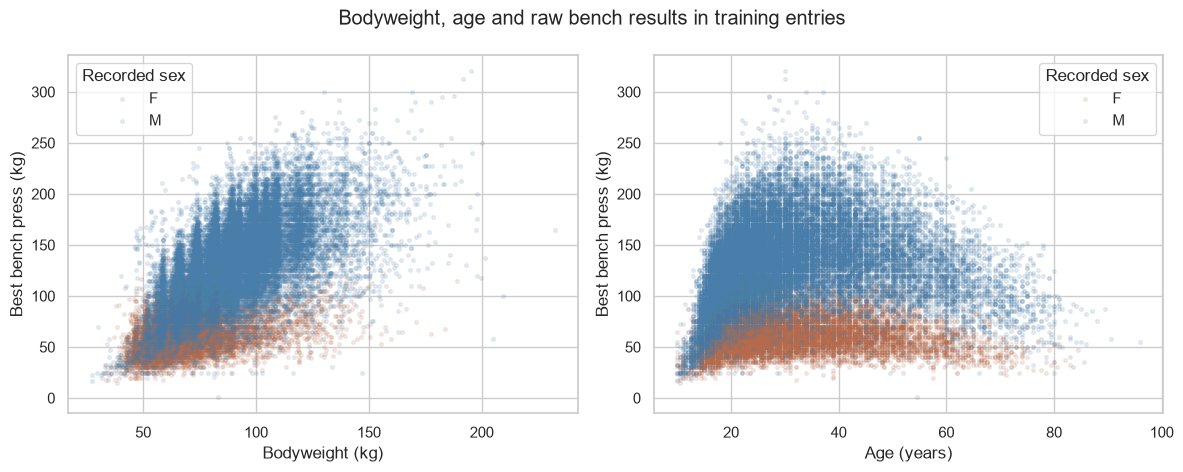

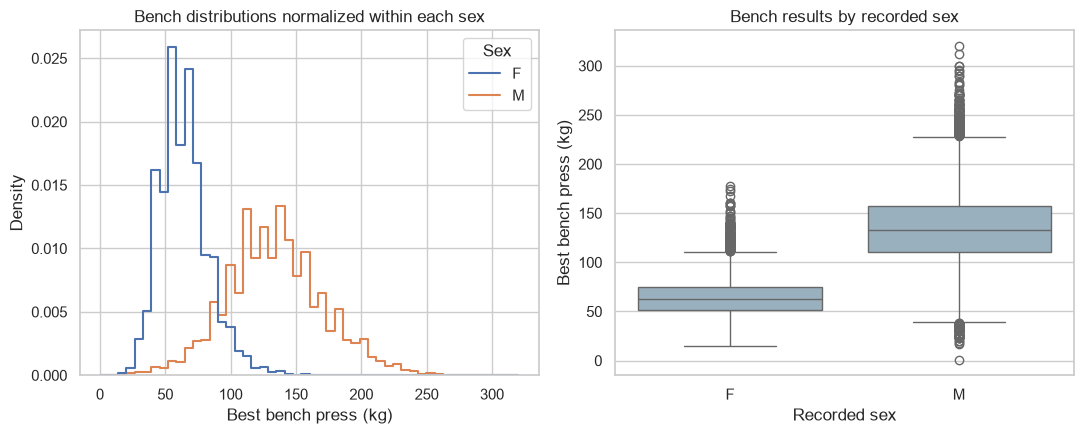

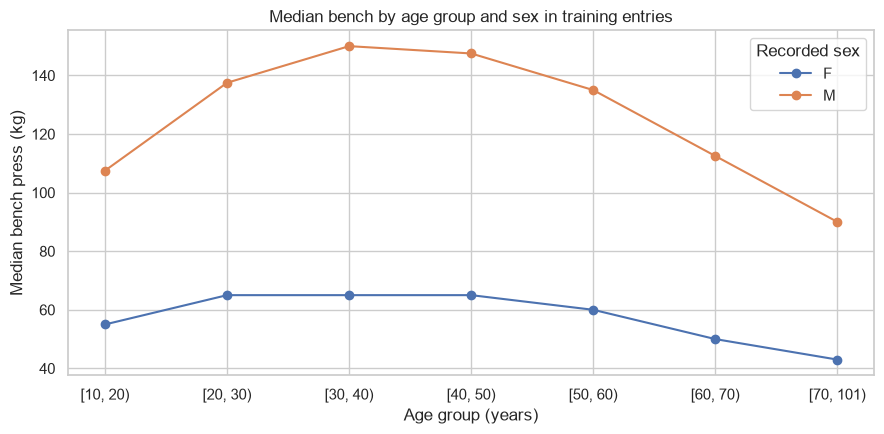

,AgeGroup,Sex,median,count
0,"[10, 20)",F,55.0,2123
1,"[10, 20)",M,107.5,6163
2,"[20, 30)",F,65.0,4341
3,"[20, 30)",M,137.5,11017
4,"[30, 40)",F,65.0,2552
5,"[30, 40)",M,150.0,5105
6,"[40, 50)",F,65.0,1642
7,"[40, 50)",M,147.5,3034
8,"[50, 60)",F,60.0,748
9,"[50, 60)",M,135.0,1691


696

In [14]:
display(train_df[['BodyweightKg','Age','Best3BenchKg']].describe().round(2))
sex_counts=pd.DataFrame({'sample':sample_df['Sex'].value_counts(),
    'training':train_df['Sex'].value_counts(),'test':test_df['Sex'].value_counts()}).reindex(['F','M'])
display(sex_counts)
summary=train_df.groupby('Sex')[['BodyweightKg','Age','Best3BenchKg']].agg(['count','median','mean','std'])
display(summary.round(2))

fig,axes=plt.subplots(1,2,figsize=(12,4.8))
for ax,feature,label in zip(axes,['BodyweightKg','Age'],['Bodyweight (kg)','Age (years)']):
    for sex,color in [('F','#b56a4c'),('M','#497eaa')]:
        group=train_df[train_df['Sex']==sex]
        ax.scatter(group[feature],group['Best3BenchKg'],s=7,alpha=.13,label=sex,color=color,rasterized=True)
    ax.set(xlabel=label,ylabel='Best bench press (kg)')
    ax.legend(title='Recorded sex')
fig.suptitle('Bodyweight, age and raw bench results in training entries')
fig.tight_layout();fig.savefig(FIGURES/'01_feature_relationships.png',dpi=170);plt.show()

fig,axes=plt.subplots(1,2,figsize=(11,4.5))
sns.histplot(data=train_df,x='Best3BenchKg',hue='Sex',stat='density',common_norm=False,
             bins=50,element='step',fill=False,ax=axes[0])
axes[0].set(xlabel='Best bench press (kg)',title='Bench distributions normalized within each sex')
sns.boxplot(data=train_df,x='Sex',y='Best3BenchKg',order=['F','M'],color='#93b1c5',ax=axes[1])
axes[1].set(xlabel='Recorded sex',ylabel='Best bench press (kg)',title='Bench results by recorded sex')
fig.tight_layout();fig.savefig(FIGURES/'02_bench_by_sex.png',dpi=170);plt.show()

age_view=train_df.assign(AgeGroup=pd.cut(train_df['Age'],bins=[10,20,30,40,50,60,70,101],right=False))
age_summary=age_view.groupby(['AgeGroup','Sex'],observed=True)['Best3BenchKg'].agg(['median','count']).reset_index()
fig,ax=plt.subplots(figsize=(9,4.5))
for sex in ['F','M']:
    group=age_summary[age_summary['Sex']==sex]
    ax.plot(group['AgeGroup'].astype(str),group['median'],marker='o',label=sex)
ax.set(xlabel='Age group (years)',ylabel='Median bench press (kg)',title='Median bench by age group and sex in training entries')
ax.legend(title='Recorded sex');fig.tight_layout();fig.savefig(FIGURES/'03_bench_by_age_group.png',dpi=170);plt.show()
display(age_summary)
eda={'training_medians_by_sex':train_df.groupby('Sex')[['BodyweightKg','Age','Best3BenchKg']].median().to_dict(),
     'training_sex_counts':train_df['Sex'].value_counts().to_dict(),
     'training_correlations':train_df[['BodyweightKg','Age','Best3BenchKg']].corr().to_dict()}
(RESULTS/'rf_exploration.json').write_text(json.dumps(eda,indent=2))

## Exploration findings
Bodyweight and bench press have a positive training correlation of 0.651, but there is considerable spread at a given bodyweight. The training median bench is 62.5 kg for recorded F entries and 132.5 kg for M entries. Median bodyweight also differs, at 66.6 and 88.2 kg, so these distributions do not isolate an effect of sex.

Age has a weak overall linear correlation with bench (0.070), but the age-group plot shows a non-linear pattern, especially among M entries. Group medians peak in middle age ranges and decrease at older ages. The groups can differ in bodyweight and other factors, so this is a cross-sectional association, not evidence of how one lifter changes over time. There are 28,210 M and 11,790 F training entries; the density plot normalizes within sex to avoid confusing frequency with distribution shape.

## Linear Regression implementation

We will implement linear regression from scratch to predict a lifter's best bench press result.

We will have two feature configurations. The first will use only bodyweight while the second will use bodyweight, age, and sex. Comparing these configurations will help us in investigating whether including age and sex increases prediction accuracy.

### Preparing Input Features and Target Values

We will start by separating the input features from the target variable.

Linear regression uses numerical targets so we will use binary encoding where 0 will represent female and 1 will represent male.

In [15]:
import numpy as np

# Model 1: Bodyweight only
X_train_body = train_df[["BodyweightKg"]].to_numpy()
X_test_body = test_df[["BodyweightKg"]].to_numpy()

# Model 2: Bodyweight, Age, and Sex
X_train_full = train_df[["BodyweightKg", "Age"]].copy()
X_test_full = test_df[["BodyweightKg", "Age"]].copy()

# Encode Sex numerically
X_train_full["Sex"] = train_df["Sex"].map({"F": 0, "M": 1})
X_test_full["Sex"] = test_df["Sex"].map({"F": 0, "M": 1})

# Convert to NumPy arrays
X_train_full = X_train_full.to_numpy()
X_test_full = X_test_full.to_numpy()

# Target variable for both models
y_train = train_df["Best3BenchKg"].to_numpy()
y_test = test_df["Best3BenchKg"].to_numpy()

# Check the dimensions
print("Bodyweight only training:", X_train_body.shape)
print("Full feature training:", X_train_full.shape)
print("Training targets:", y_train.shape)

Bodyweight only training: (40000, 1)
Full feature training: (40000, 3)
Training targets: (40000,)


### Feature Scaling

We will now standardize the input features so they are on comparable numerical scales. This will make optimization easier for gradient descent. We will do this by using StandardScaler().

In [16]:
from sklearn.preprocessing import StandardScaler

# Scale bodyweight features
body_scaler = StandardScaler()

X_train_body_scaled = body_scaler.fit_transform(X_train_body)
X_test_body_scaled = body_scaler.transform(X_test_body)

# Scale all three features
full_scaler = StandardScaler()

X_train_full_scaled = full_scaler.fit_transform(X_train_full)
X_test_full_scaled = full_scaler.transform(X_test_full)

### Implementing Linear Regression From Scratch

We will not be using a pre build regression model. We will instead build the model from scratch using NumPy.

We will use gradient descent in order to determine coefficients that will minimize mean squared error or MSE for short between the predicted and actual bench press results.

During training the model will repeatedly calculate predictions. It will measure errors and continuously update coefficients to improve prediction accuracy.

In [17]:
class LinearRegressionScratch:
    def __init__(self, learning_rate=0.1, epochs=500):
        self.learning_rate = learning_rate
        self.epochs = epochs

    def fit(self, X, y):
        n_samples, n_features = X.shape

        # Initialize coefficients
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        self.loss_history = []

        for _ in range(self.epochs):
            # Calculate predictions and errors
            predictions = X @ self.weights + self.bias
            errors = predictions - y

            # Calculate gradients
            dw = (2 / n_samples) * (X.T @ errors)
            db = (2 / n_samples) * errors.sum()

            # Update coefficients
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db

            # Record training error
            self.loss_history.append(np.mean(errors ** 2))

    def predict(self, X):
        return X @ self.weights + self.bias

In [18]:
# Train bodyweight only model
body_model = LinearRegressionScratch()
body_model.fit(X_train_body_scaled, y_train)

# Train full feature model
full_model = LinearRegressionScratch()
full_model.fit(X_train_full_scaled, y_train)

# Display final training errors
print("Bodyweight only training MSE:", round(body_model.loss_history[-1], 2))
print("Full feature training MSE:", round(full_model.loss_history[-1], 2))

Bodyweight only training MSE: 1211.49
Full feature training MSE: 768.7


### Linear Regression Training Findings

The Bodyweight Only Training model had a MSE of 1211.49 while the Full Feature Training model had a MSE of 768.7. This indicates the full feature model had approximately a 36.5% lower training error. This suggests including age and sex does in fact increase accuracy. 

However, these results are not final. Both models still need to be evaluated on test data to determine how well they perform on unseen data.

### Checking Gradient Descent Convergence

We will plot the MSE across the 500 epochs for both models. This is in order to examine how the error changes during training.

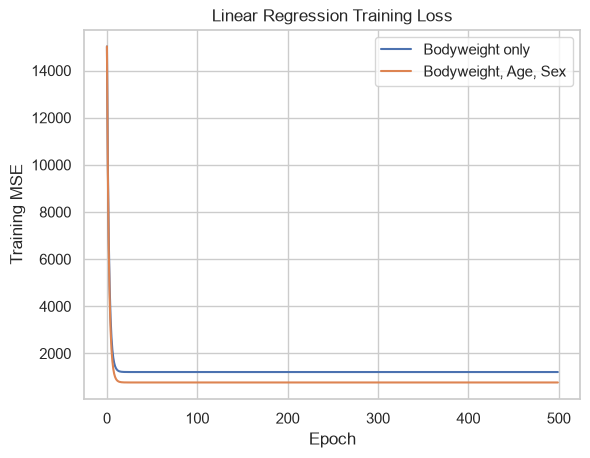

In [19]:
import matplotlib.pyplot as plt

plt.plot(body_model.loss_history, label="Bodyweight only")
plt.plot(full_model.loss_history, label="Bodyweight, Age, Sex")

plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Linear Regression Training Loss")
plt.legend()
plt.show()

### Gradient Descent Convergence Findings

As you can see in the graph from about epoch 0-10 the Training MSE was very high. At around epoch 10-20 and onward the Training MSE stabilized as seen in the flattening curve. This is indicative of gradient descent being converged.

These results suggest 500 epochs were sufficient for both models to converge. The full feature model achieved a lower training error.

## Feature preparation and model selection
Both configurations use the same training/test entries and target values. We encode recorded sex as F=0 and M=1, matching the existing Linear Regression preparation. This is a binary category, not a continuous measure. Random Forest does not need StandardScaler because its trees split features at thresholds; we use the original numerical units.

A Random Forest averages predictions from many decision trees trained on bootstrap samples. Each tree learns splits that reduce squared prediction error. Averaging can reduce variance, while tree depth and leaf size control how closely the forest follows individual observations. A forest does not extrapolate beyond the range of its training target values.

We fix 150 trees and `random_state=42` for reproducibility. For each feature configuration we compare the default depth/leaf settings with a small grid: unlimited depth with leaf sizes 1, 5 or 20, and depth 10 with leaf sizes 5 or 20. Five shuffled KFold splits use the same row positions for both models. We select the lowest CV RMSE because large kilogram errors matter, and also record MAE and R². The test set is not used for selection. Grid CV scores are selection results, not an independent estimate after tuning.

In [20]:
def feature_frame(frame,full=False):
    X=frame[['BodyweightKg']].copy()
    if full:
        X['Age']=frame['Age']
        X['Sex']=frame['Sex'].map({'F':0,'M':1})
    assert not X.isna().any().any()
    return X

y_train=train_df['Best3BenchKg']
y_test=test_df['Best3BenchKg']
rf_inputs={
    'A Bodyweight only':(feature_frame(train_df),feature_frame(test_df)),
    'B Bodyweight + age + sex':(feature_frame(train_df,True),feature_frame(test_df,True)),
}
cv=list(KFold(n_splits=5,shuffle=True,random_state=42).split(train_df))
scoring={'mae':'neg_mean_absolute_error','rmse':'neg_root_mean_squared_error','r2':'r2'}
grid=[{'max_depth':[None],'min_samples_leaf':[1,5,20]},
      {'max_depth':[10],'min_samples_leaf':[5,20]}]
rf_searches={}
cv_rows=[]
for name,(X_train,X_test) in rf_inputs.items():
    print('Selecting',name,flush=True)
    forest=RandomForestRegressor(n_estimators=150,random_state=42,n_jobs=2)
    search=GridSearchCV(forest,grid,cv=cv,scoring=scoring,refit='rmse',
        n_jobs=1,return_train_score=True,error_score='raise')
    search.fit(X_train,y_train)
    rf_searches[name]=search
    table=pd.DataFrame(search.cv_results_)
    default_index=next(i for i,p in enumerate(table['params']) if p['max_depth'] is None and p['min_samples_leaf']==1)
    for label,index in [('Starting',default_index),('Selected',search.best_index_)]:
        row=table.iloc[index]
        cv_rows.append({'configuration':name,'version':label,
           'MAE':-row['mean_test_mae'],'RMSE':-row['mean_test_rmse'],'R2':row['mean_test_r2'],
           'RMSE_fold_SD':row['std_test_rmse'],'settings':row['params']})
    table.to_json(RESULTS/('rf_'+name[0].lower()+'_grid.json'),orient='records',indent=2)
    print('Selected:',search.best_params_)
cv_comparison=pd.DataFrame(cv_rows)
display(cv_comparison)
cv_comparison.to_json(RESULTS/'rf_cv_comparison.json',orient='records',indent=2)

Selecting A Bodyweight only
Selected: {'max_depth': 10, 'min_samples_leaf': 20}
Selecting B Bodyweight + age + sex
Selected: {'max_depth': 10, 'min_samples_leaf': 20}


,configuration,version,MAE,RMSE,R2,RMSE_fold_SD,settings
0,A Bodyweight only,Starting,26.878555,34.910170,0.420194,0.225299,"{'max_depth': None, 'min_samples_leaf': 1}"
1,A Bodyweight only,Selected,25.884570,33.388753,0.469635,0.194826,"{'max_depth': 10, 'min_samples_leaf': 20}"
2,B Bodyweight + age + sex,Starting,20.477328,26.916700,0.655311,0.175194,"{'max_depth': None, 'min_samples_leaf': 1}"
3,B Bodyweight + age + sex,Selected,18.239171,23.997269,0.726024,0.186016,"{'max_depth': 10, 'min_samples_leaf': 20}"


### Evaluating Linear Regression Models

We will now evaluate performance using the test dataset. 

Three metrics will be used:
- MAE: Mean Absolute Error which will measure the absolute difference between predicted and actual bench press results
- RMSE: Root Mean Squared Error which will indicate larger mistakes
- R²: Measures how much of the variation in bench press strength is explained by the model.

By including multiple metrics we will be able to determine whether the inclusion of age and sex increased prediction accuracy on unseen data.

In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Make predictions on the test data
body_predictions = body_model.predict(X_test_body_scaled)
full_predictions = full_model.predict(X_test_full_scaled)

# Evaluate the bodyweight model
print("Bodyweight only Linear Regression:")
print("MAE:", round(mean_absolute_error(y_test, body_predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, body_predictions)), 2))
print("R²:", round(r2_score(y_test, body_predictions), 3))

# Evaluate the full feature model
print("\nBodyweight, Age, Sex Linear Regression:")
print("MAE:", round(mean_absolute_error(y_test, full_predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, full_predictions)), 2))
print("R²:", round(r2_score(y_test, full_predictions), 3))

Bodyweight only Linear Regression:
MAE: 27.86
RMSE: 35.09
R²: 0.417

Bodyweight, Age, Sex Linear Regression:
MAE: 21.41
RMSE: 28.05
R²: 0.627


### Linear Regression Evaluation Findings

Both models were evaluated using the same entries (10000). 

The results were the following:
**Bodyweight Only:**
- MAE: 27.86
- RMSE: 35.09
- R²: 0.417

**Bodyweight, Age, and Sex**
- MAE: 21.41
- RMSE: 28.05
- R²: 0.627

As demonstrated by the results including age and sex increased model accuracy. The average absolute prediction error decreased by about 23.2% while the R² increased from 
41.7% to 62.7%. The R² value indicates the full feature model explains more of the variation in bench press strength.

These results suggest age and sex are useful additional metrics when predicting raw bench press strength. The model does however still have prediction errors.

### Visualizing Linear Regression Predictions

A scatterplot will be created for each model. A diagonal line will represent perfect predictions meaning a representation of the actual values. The closer the points are to the line the more accurate the predictions are. 

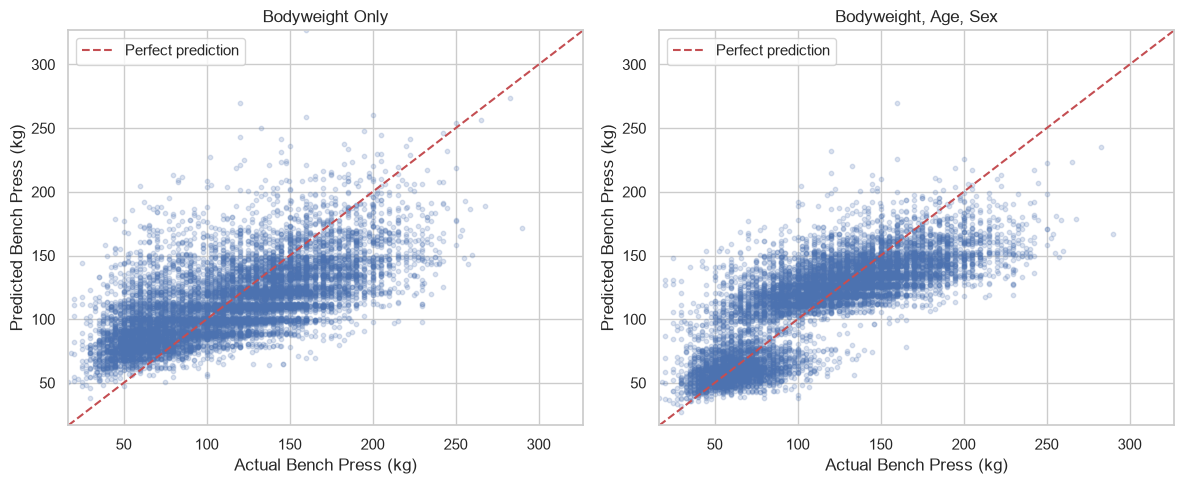

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Determine common axis limits for both plots
min_val = min(y_test.min(), body_predictions.min(), full_predictions.min())
max_val = max(y_test.max(), body_predictions.max(), full_predictions.max())

# Plot predictions for both models
models = [
    ("Bodyweight Only", body_predictions),
    ("Bodyweight, Age, Sex", full_predictions)
]

for ax, (title, predictions) in zip(axes, models):
    ax.scatter(y_test, predictions, alpha=0.2, s=10)
    ax.plot([min_val, max_val], [min_val, max_val], "r--",
            label="Perfect prediction")

    ax.set_title(title)
    ax.set_xlabel("Actual Bench Press (kg)")
    ax.set_ylabel("Predicted Bench Press (kg)")
    ax.set_xlim(min_val, max_val)
    ax.set_ylim(min_val, max_val)
    ax.legend()

plt.tight_layout()
plt.show()

## Final evaluation
GridSearchCV refits each selected forest on all 40,000 training entries. We now evaluate the fixed models on the same 10,000 test entries. MAE is the average absolute kilogram error, RMSE gives more weight to large errors, and R² compares squared error with predicting the test-target mean. We also show training errors to look for signs of overfitting. A smaller training error alone is not evidence of better predictions.

,configuration,split,MAE,RMSE,R2
0,A Bodyweight only,Training,25.2914,32.6224,0.4938
1,A Bodyweight only,Test,26.0989,33.6400,0.4642
2,B Bodyweight + age + sex,Training,17.7730,23.4325,0.7388
3,B Bodyweight + age + sex,Test,18.2838,24.2099,0.7225


MAE reduction from added features (%): 29.94
RMSE reduction from added features (%): 28.03
R2 change: 0.2583


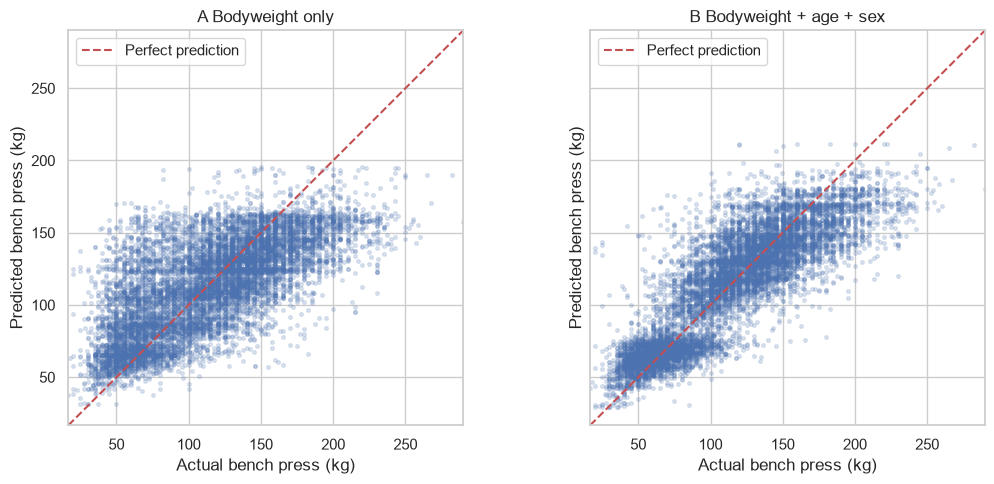

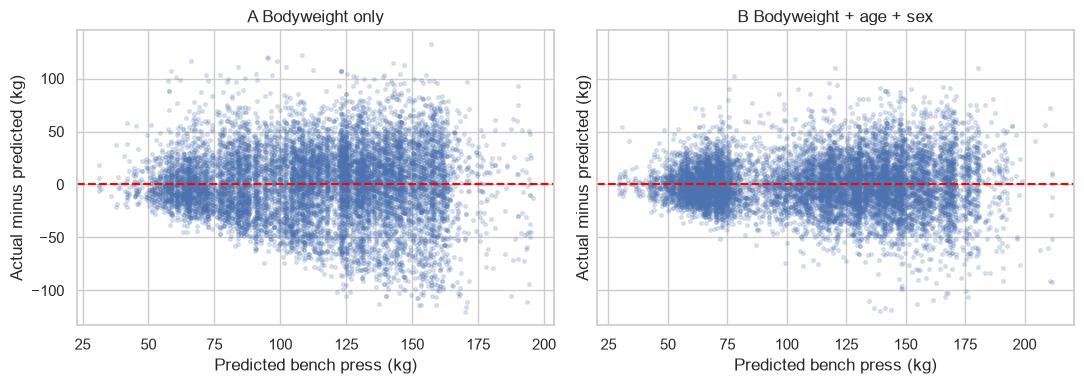

,configuration,Sex,n,MAE,RMSE,R2
0,A Bodyweight only,F,2948,28.081,36.535,-2.632
1,A Bodyweight only,M,7052,25.270,32.353,0.258
2,B Bodyweight + age + sex,F,2948,13.028,16.913,0.222
3,B Bodyweight + age + sex,M,7052,20.481,26.675,0.495


711

In [23]:
def metric_row(actual,predicted):
    return {'MAE':float(mean_absolute_error(actual,predicted)),
            'RMSE':float(np.sqrt(mean_squared_error(actual,predicted))),
            'R2':float(r2_score(actual,predicted))}

rf_metrics=[]
rf_predictions={}
for name,(X_train,X_test) in rf_inputs.items():
    model=rf_searches[name].best_estimator_
    train_predictions=model.predict(X_train)
    predictions=model.predict(X_test)
    rf_predictions[name]=predictions
    for split,actual,pred in [('Training',y_train,train_predictions),('Test',y_test,predictions)]:
        rf_metrics.append({'configuration':name,'split':split,**metric_row(actual,pred)})
rf_results=pd.DataFrame(rf_metrics)
display(rf_results.round(4))
rf_results.to_json(RESULTS/'rf_metrics.json',orient='records',indent=2)
pd.DataFrame({'actual_kg':y_test,**rf_predictions}).to_json(RESULTS/'rf_test_predictions.json',orient='records')
params={name:search.best_params_ for name,search in rf_searches.items()}
(RESULTS/'rf_selected_parameters.json').write_text(json.dumps(params,indent=2))

test_results=rf_results[rf_results['split']=='Test'].set_index('configuration')
a,b=test_results.iloc[0],test_results.iloc[1]
print('MAE reduction from added features (%):',round(100*(a.MAE-b.MAE)/a.MAE,2))
print('RMSE reduction from added features (%):',round(100*(a.RMSE-b.RMSE)/a.RMSE,2))
print('R2 change:',round(b.R2-a.R2,4))

fig,axes=plt.subplots(1,2,figsize=(11,5),sharex=True,sharey=True)
lo=min(y_test.min(),min(p.min() for p in rf_predictions.values()))
hi=max(y_test.max(),max(p.max() for p in rf_predictions.values()))
for ax,(name,pred) in zip(axes,rf_predictions.items()):
    ax.scatter(y_test,pred,s=7,alpha=.18)
    ax.plot([lo,hi],[lo,hi],'r--',label='Perfect prediction')
    ax.set(title=name,xlabel='Actual bench press (kg)',ylabel='Predicted bench press (kg)',xlim=(lo,hi),ylim=(lo,hi))
    ax.legend();ax.set_aspect('equal',adjustable='box')
fig.tight_layout();fig.savefig(FIGURES/'04_rf_actual_vs_predicted.png',dpi=170);plt.show()

fig,axes=plt.subplots(1,2,figsize=(11,4),sharey=True)
for ax,(name,pred) in zip(axes,rf_predictions.items()):
    ax.scatter(pred,y_test.to_numpy()-pred,s=7,alpha=.18)
    ax.axhline(0,color='red',linestyle='--')
    ax.set(title=name,xlabel='Predicted bench press (kg)',ylabel='Actual minus predicted (kg)')
fig.tight_layout();fig.savefig(FIGURES/'05_rf_residuals.png',dpi=170);plt.show()

subgroups=[]
for name,pred in rf_predictions.items():
    for sex in ['F','M']:
        mask=test_df['Sex'].eq(sex)
        subgroups.append({'configuration':name,'Sex':sex,'n':int(mask.sum()),**metric_row(y_test[mask],pred[mask])})
display(pd.DataFrame(subgroups).round(3))
(RESULTS/'rf_metrics_by_sex.json').write_text(json.dumps(subgroups,indent=2))

## Random Forest findings
The bodyweight-only forest achieved test MAE 26.10 kg, RMSE 33.64 kg and R² 0.464. Adding age and sex changed these to MAE 18.28 kg, RMSE 24.21 kg and R² 0.722. The added features reduced MAE by 29.9% and RMSE by 28.0% on the same test entries. This supports their joint predictive usefulness in this sample, not a causal interpretation or a separate estimate of each feature's contribution.

Training RMSE was 32.62 kg for A and 23.43 kg for B, compared with 33.64 and 24.21 kg on the test set. These relatively small gaps give limited evidence of overfitting in the selected forests. CV selected regularization without inspecting test predictions. The prediction plots show that both forests tend to pull extreme results towards the middle. High actual bench results are often underpredicted. Model B lies closer to the perfect-prediction line overall, but some large errors remain.

| Model | MAE (kg) | RMSE (kg) | R² |
| --- | --- | --- | --- |
| A Bodyweight only | 26.10 | 33.64 | 0.464 |
| B Bodyweight + age + sex | 18.28 | 24.21 | 0.722 |


## Interpretation and limitations
Adding age and sex is a joint comparison; these two configurations cannot show how much improvement comes from each added feature on its own. Associations in these competition records do not establish causal effects.

We preserve the existing random entry split. Lifters can appear at multiple meets, so a test entry may belong to someone whose other entries were used in training. The provenance audit checks approximate name overlap, but names are not unique athlete identifiers. Results describe held-out competition entries, not necessarily previously unseen lifters. A future athlete-grouped split would test that more strictly and would need to be shared by all four model configurations.

The sample excludes missing ages and recorded Mx entries, and only includes positive successful raw bench results for ages 10-100. It represents those selected competition entries rather than the general population. Extreme results may be harder to predict because there are fewer similar training entries. Forests can overfit and do not extrapolate well, so training/test gaps and residuals need to be considered alongside overall scores.

In [24]:
print('Approximate name overlap audit:')
for key in ['unique_train_names','unique_test_names','overlapping_name_labels','test_rows_with_name_seen_in_training']:
    print(key+':',provenance[key])
print(provenance['identity_audit_note'])
fingerprints={name:hashlib.sha256(Path(name).read_bytes()).hexdigest()
              for name in ['bench_press_sample.csv','bench_train.csv','bench_test.csv']}
(RESULTS/'shared_csv_sha256.json').write_text(json.dumps(fingerprints,indent=2))
assert all(len(pred)==10000 for pred in rf_predictions.values())
print('Both forests used the same 40,000 training and 10,000 test entries.')

Approximate name overlap audit:
unique_train_names: 36558
unique_test_names: 9775
overlapping_name_labels: 1557
test_rows_with_name_seen_in_training: 1640
Name is an approximate label, not a unique athlete identifier. Names are not model inputs.
Both forests used the same 40,000 training and 10,000 test entries.


## Comparing all four configurations
We calculate the same three metrics on the same 10,000 test entries. MAE measures the average absolute error in kilograms, RMSE emphasizes large errors, and R² describes improvement over predicting the test-target mean. We compare feature sets within each algorithm as well as algorithms using the same features.

,algorithm,features,MAE,RMSE,R2
0,Linear Regression from scratch,Bodyweight only,27.8560,35.0858,0.4172
1,Linear Regression from scratch,Bodyweight + age + sex,21.4069,28.0529,0.6274
2,Random Forest,Bodyweight only,26.0989,33.6400,0.4642
3,Random Forest,Bodyweight + age + sex,18.2838,24.2099,0.7225


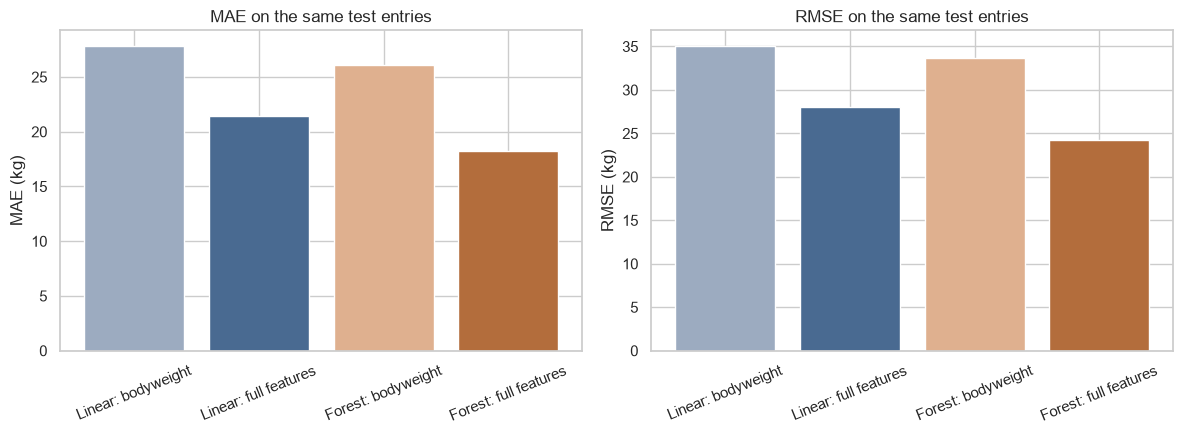

Linear Regression from scratch : added-feature MAE reduction 23.15 %, RMSE reduction 20.04 %
Random Forest : added-feature MAE reduction 29.94 %, RMSE reduction 28.03 %
All four configurations share the same training/test rows and metric definitions.


In [25]:
comparison_rows=[]
for features,pred in [('Bodyweight only',body_predictions),('Bodyweight + age + sex',full_predictions)]:
    comparison_rows.append({'algorithm':'Linear Regression from scratch','features':features,**metric_row(y_test,pred)})
for name,pred in rf_predictions.items():
    comparison_rows.append({'algorithm':'Random Forest','features':name[2:],**metric_row(y_test,pred)})
comparison=pd.DataFrame(comparison_rows)
display(comparison.round(4))
comparison.to_json(RESULTS/'four_configuration_comparison.json',orient='records',indent=2)

fig,axes=plt.subplots(1,2,figsize=(12,4.5))
labels=['Linear: bodyweight','Linear: full features','Forest: bodyweight','Forest: full features']
for ax,metric in zip(axes,['MAE','RMSE']):
    ax.bar(labels,comparison[metric],color=['#9cabc0','#496a91','#dfb08f','#b36d3c'])
    ax.set(ylabel=metric+' (kg)',title=metric+' on the same test entries')
    ax.tick_params(axis='x',rotation=22)
fig.tight_layout();fig.savefig(FIGURES/'06_four_model_comparison.png',dpi=170);plt.show()

for algorithm,group in comparison.groupby('algorithm',sort=False):
    a,b=group.iloc[0],group.iloc[1]
    print(algorithm,': added-feature MAE reduction',round(100*(a.MAE-b.MAE)/a.MAE,2),'%, RMSE reduction',round(100*(a.RMSE-b.RMSE)/a.RMSE,2),'%')
assert len(comparison)==4
assert np.isclose(comparison.iloc[0].MAE,27.86,atol=.005)
assert np.isclose(comparison.iloc[1].MAE,21.41,atol=.005)
assert all(len(p)==len(y_test)==10000 for p in rf_predictions.values())
print('All four configurations share the same training/test rows and metric definitions.')

## Discussion and conclusion
Adding age and sex improved both algorithms on the shared test set. Linear Regression MAE fell from 27.86 to 21.41 kg, while Random Forest MAE fell from 26.10 to 18.28 kg. The full-feature forest achieved the lowest MAE and RMSE and the highest R² of the four configurations: 18.28 kg, 24.21 kg and 0.722. We recommend it among the configurations tested.

The forest can represent non-linear relationships and combinations of features, which may help explain its lower error. Linear Regression is simpler and more transparent, but assumes a linear relationship after the numerical feature preparation. The forest was selected using a small CV grid, while the linear models used fixed gradient-descent settings and a convergence check; the comparison is specific to these implementations, not proof that forests always perform better.

Age and sex were added together, so the experiment establishes their joint predictive value rather than the separate contribution of either feature. The associations are not causal. The selected forests have relatively small training/test error gaps, but extreme results remain difficult to predict.

The split is by competition entry, not athlete. Some test entries share name labels with training entries, and names are imperfect identifiers. Results therefore concern held-out entries rather than guaranteed unseen lifters. Missing-age exclusions, the F/M restriction, the selected age range and the sample of raw competition results also limit generalization. Future work could use a shared athlete-grouped split and examine the added features separately.

## Sources
Data: [OpenPowerlifting Data Service](https://openpowerlifting.gitlab.io/opl-csv/), September 19 snapshot. The dataset contains competition results and is used here to predict successful raw bench results.

Implementation reference: [scikit-learn RandomForestRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html). Linear Regression is implemented directly with NumPy and gradient descent; no ready-made Linear Regression estimator is used.